# Predicting Diabetes Progression – A Screening Tool for Physicians

**Lab:** Regression & classification on the Scikit-Learn Diabetes dataset

**Goal:** build a model that can best predict the risk of diabetes progression one year after baseline,
so physicians can identify patients at risk.

### Notebook structure
| Part | Steps |
|---|---|
| **Part 1 – Data** | 1. Get the data · 2. Frame the problem · 3. EDA · 4. Cleaning · 5. Train / validation / test split |
| **Part 2 – Univariate polynomial regression (BMI)** | 6. Models · 7. Comparison table · 8. Best model · 9. Test results · 10. Plot · 11. Equation · 12. Prediction · 13. Parameters · 14. Conclusion |
| **Part 3 – Multivariate models** | Polynomial · Decision tree · kNN · Logistic regression (steps 6–14 repeated) |

### How the code is organised
To keep this notebook short and readable, the reusable code lives in **classes** in the `src/` folder
(Object-Oriented Programming). The notebook only *uses* those classes:

| File | Class | Job |
|---|---|---|
| `src/data_loader.py` | `DiabetesDataLoader` | loads the dataset |
| `src/eda.py` | `DataExplorer` | statistics and EDA plots |
| `src/data_splitter.py` | `DataSplitter` | train / validation / test split |
| `src/model_builder.py` | `ModelBuilder` | creates every model, counts parameters, writes equations |
| `src/model_evaluator.py` | `ModelEvaluator` | computes metrics, builds comparison tables, plots results |

In [1]:
# --- Imports ---
# Standard data-science libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Our own classes from the src/ folder
from src import DiabetesDataLoader, DataExplorer, DataSplitter, ModelBuilder, ModelEvaluator

# Settings: show all columns of wide tables, and fix the random seed for reproducibility
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
RANDOM_STATE = 42

---
# Part 1 – The Data

## Step 1 – Get the data

We load the data with `datasets.load_diabetes()` (wrapped inside our `DiabetesDataLoader` class) and use two optional arguments:

* `as_frame=True` → we get a **pandas DataFrame** (with column names) instead of plain NumPy arrays.
* `scaled=False` → we keep the **original units** (BMI in kg/m², blood pressure in mm Hg, …).
  By default sklearn returns the features already mean-centred and scaled, which makes values like `bmi = 0.06`
  meaningless to a physician. With the original units our final equation can be read directly ("BMI = 30").
  When a model needs scaling (kNN, logistic regression), we do it later **inside a Pipeline**, using the training data only.
* We do **not** use `return_X_y=True` because we want the full object (it also contains the description text).

In [2]:
loader = DiabetesDataLoader(scaled=False)
df = loader.load()

print(f"Shape of the data: {df.shape[0]} rows (patients) x {df.shape[1]} columns")
df.head()

Shape of the data: 442 rows (patients) x 11 columns


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


### Dataset description
As requested, we read the official description before exploring the data (only the first part is printed here):

In [3]:
print(loader.get_description()[:1700])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [4]:
# What each column means (from the description above)
loader.feature_table()

,column,meaning
0,age,Age in years
1,sex,Sex (1 or 2)
2,bmi,Body mass index (kg/m^2)
3,bp,Average blood pressure (mm Hg)
4,s1,tc - total serum cholesterol
5,s2,ldl - low-density lipoproteins
6,s3,hdl - high-density lipoproteins
7,s4,tch - total cholesterol / HDL
8,s5,ltg - log of serum triglycerides level
9,s6,glu - blood sugar level


## Step 2 – Frame the problem

**What are we predicting?**
The target is a *quantitative measure of disease progression one year after baseline*. "Baseline" is the moment the
10 measurements (age, sex, BMI, blood pressure and six blood serum results) were taken. So the question is:

> *Given what we measure about a patient today, how much will their diabetes progress over the next year?*

**What type of ML problem is it?**
* **Supervised learning** – every patient has a known answer (the target), so the model can learn from examples.
* **Regression** – the target is a continuous number (25 to 346), not a category.
  This is why we use regression models (polynomial regression, decision-tree regressor, kNN regressor).
* It can **also be framed as classification**: a physician often just wants to know *"is this patient high risk or not?"*.
  If we turn the target into two classes (high / low progression) we can use a **logistic regression classifier** (Part 3).

**How will the model be used?** As a **screening tool**: it flags patients who may need closer follow-up.
It supports – but does not replace – the physician's judgement.

**How do we measure success?**
For regression models we use the three metrics given in the lab:

| Metric | Meaning | Good value |
|---|---|---|
| **R²** | share of the variation in progression the model explains | close to 1 (0 = no better than guessing the average) |
| **MAE** | average size of the error, in target units | small |
| **MAPE** | average error as a % of the true value | small |

A natural **baseline** is a model that always predicts the average progression (this is our degree-0 polynomial).
Any useful model must beat it.

**Talking points from the workshops**

*Performance Metrics for Classification*
* For the classification framing we look at the **confusion matrix**: true positives, false positives, true negatives, false negatives.
* **Accuracy** alone can be misleading, especially if one class is much bigger than the other.
* **Precision** = of the patients we flag, how many are really high risk? **Recall (sensitivity)** = of the patients who are really high risk, how many do we catch?
* In **screening, a false negative is the costly mistake** (a high-risk patient is told they are fine and gets no follow-up).
  A false positive "only" costs an extra check-up. So **recall is the most important classification metric** here, with F1 as a balance.

*K-Nearest Neighbours*
* kNN predicts by looking at the *k* most similar patients in the training data and averaging their outcomes – intuitive for doctors ("patients like this one…").
* It is based on **distance**, so features **must be scaled**, otherwise cholesterol (~190) would dominate s5 (~4.6).
* The choice of *k* is a **bias–variance trade-off**: small k → follows the noise (overfits), large k → too smooth (underfits).
* It has **no trainable parameters** – it just stores the training data ("lazy learner") – and suffers when there are many irrelevant features (curse of dimensionality).

*Logistic Regression*
* Despite its name, logistic regression is a **classifier**: it passes a linear combination of the features through the **sigmoid** function
  to get a **probability** between 0 and 1 of being high risk.
* The default decision **threshold is 0.5**, but for screening it can be lowered to catch more high-risk patients (higher recall, lower precision).
* Its coefficients are easy to explain: a positive coefficient increases the log-odds of being high risk.

## Step 3 – Exploratory Data Analysis (EDA)

### 3.1 Data types, missing values and duplicates

In [5]:
explorer = DataExplorer(df, target="target")

print(f"Duplicate rows: {explorer.count_duplicates()}")
explorer.data_quality_report()

Duplicate rows: 0


,dtype,missing_values,unique_values
age,float64,0,58
sex,float64,0,2
bmi,float64,0,163
bp,float64,0,100
s1,float64,0,141
s2,float64,0,302
s3,float64,0,63
s4,float64,0,66
s5,float64,0,184
s6,float64,0,56


**Insight:** all 11 columns are numeric (`float64`), there are **no missing values** and **no duplicate rows**.
`sex` has only 2 unique values (1 and 2), so it is really a *categorical* (binary) variable stored as a number.
`s4` has relatively few unique values (it is a ratio that is often a whole number).

### 3.2 Summary statistics

In [6]:
explorer.summary_statistics()

,count,mean,std,min,25%,50%,75%,max
age,442.0,48.52,13.11,19.00,38.25,50.00,59.00,79.00
sex,442.0,1.47,0.50,1.00,1.00,1.00,2.00,2.00
bmi,442.0,26.38,4.42,18.00,23.20,25.70,29.28,42.20
bp,442.0,94.65,13.83,62.00,84.00,93.00,105.00,133.00
s1,442.0,189.14,34.61,97.00,164.25,186.00,209.75,301.00
s2,442.0,115.44,30.41,41.60,96.05,113.00,134.50,242.40
s3,442.0,49.79,12.93,22.00,40.25,48.00,57.75,99.00
s4,442.0,4.07,1.29,2.00,3.00,4.00,5.00,9.09
s5,442.0,4.64,0.52,3.26,4.28,4.62,5.00,6.11
s6,442.0,91.26,11.50,58.00,83.25,91.00,98.00,124.00


**Insights from the statistics**
* **442 patients**, aged 19–79 (mean ≈ 48.5 years).
* **BMI** ranges from 18 to 42.2 (mean ≈ 26.4) – on average the patients are slightly overweight.
* The **target** ranges from 25 to 346 with mean ≈ 152 and median 140.5. Mean > median → the target is **right-skewed**
  (a smaller group of patients has a very high progression).
* The features have **very different scales** (s5 ≈ 4.6, s1 ≈ 189). This matters for distance-based models (kNN) → we will scale them inside the model pipelines.

### 3.3 Histograms

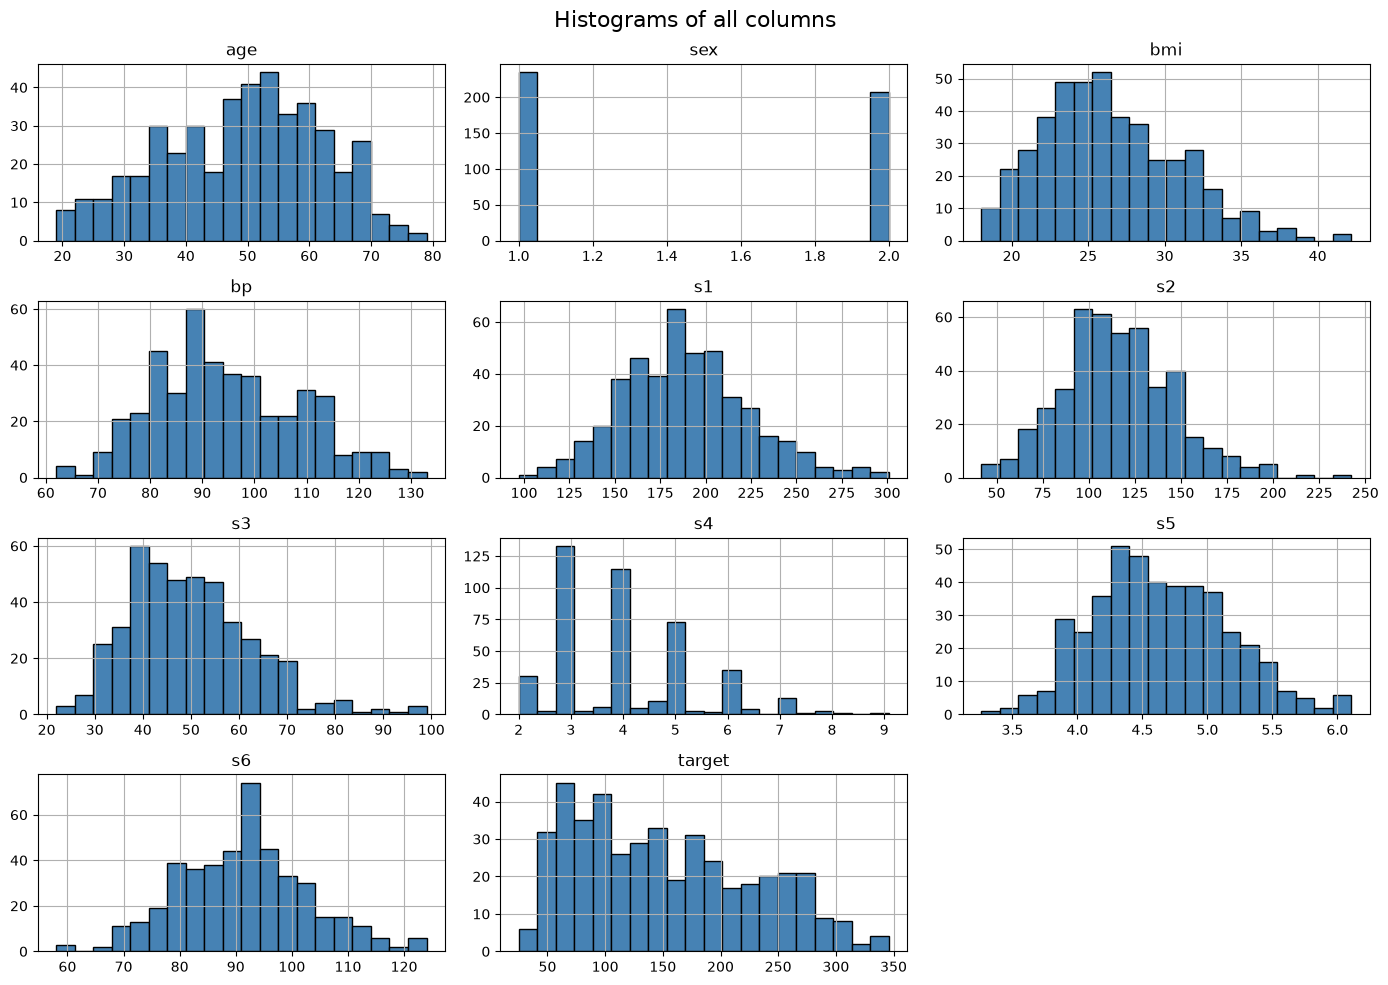

In [7]:
explorer.plot_histograms()

**Insights from the histograms**
* **Target:** right-skewed – many patients between 50 and 150, fewer above 250.
* **BMI** is also right-skewed (a tail of patients with high BMI); **s3 (HDL)** and **s4** are right-skewed as well.
* **age, bp, s1, s2, s5, s6** look roughly bell-shaped (approximately normal).
* **sex** shows only two bars → binary variable, with slightly more patients coded 1 than 2.
* **s4** shows "spikes" at whole numbers (3, 4, 5…), so it behaves almost like a discrete variable.

### 3.4 Scatter plots: each feature vs. the target

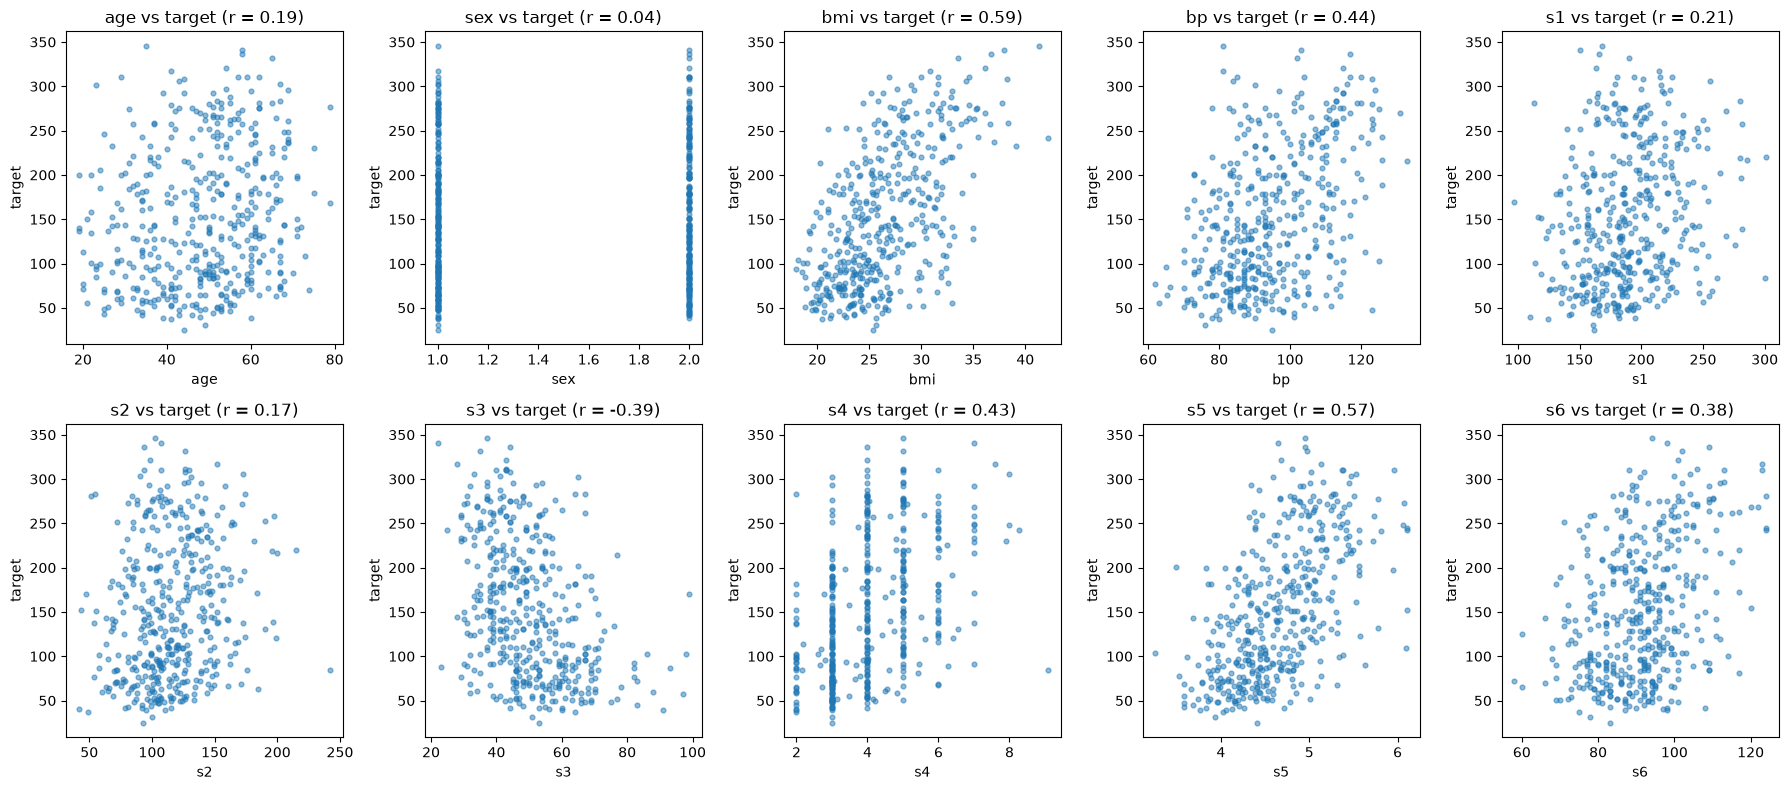

In [8]:
explorer.plot_scatter_vs_target()

**Insights from the scatter plots**
* **BMI** and **s5** show the clearest upward trend: higher BMI / higher triglycerides → more progression.
* **bp**, **s4** and **s6** show weaker positive trends; **s3 (HDL, the "good" cholesterol)** shows a downward trend.
* **age, sex, s1, s2** show almost no visible pattern.
* Even for BMI the cloud of points is **very wide**: patients with the same BMI can have a progression of 50 or 300.
  So we should not expect any single feature to predict the target very accurately.
* The BMI trend looks **mostly straight (linear)**, without a clear curve – a hint that a high-degree polynomial may not add much.

### 3.5 Correlation matrix

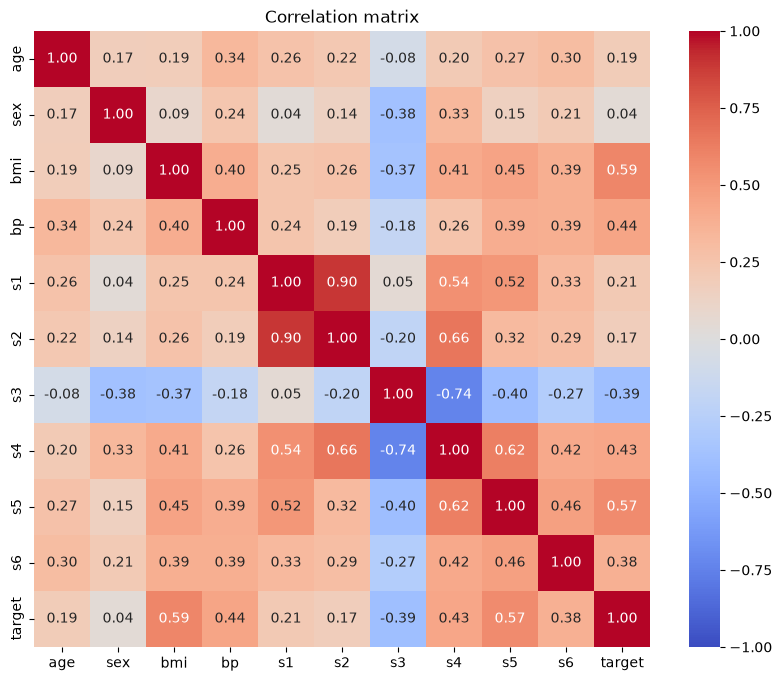

In [9]:
explorer.plot_correlation_matrix()

In [10]:
print("Correlation of each feature with the target (sorted by strength):")
explorer.target_correlations()

Correlation of each feature with the target (sorted by strength):


bmi    0.59
s5     0.57
bp     0.44
s4     0.43
s3    -0.39
s6     0.38
s1     0.21
age    0.19
s2     0.17
sex    0.04
Name: target, dtype: float64

**Insights from the correlation matrix**
* Strongest relationships with the target: **bmi (0.59)** and **s5 (0.57)**, then **bp (0.44)**, **s4 (0.43)**, **s3 (−0.39)** and **s6 (0.38)**.
  This supports using **BMI for the univariate model** in Part 2.
* Weak relationships: **s1 (0.21)**, **age (0.19)**, **s2 (0.17)** and especially **sex (0.04)** – nearly zero.
* **Multicollinearity** (features strongly related to each other):
  * **s1 and s2: 0.90** – total cholesterol and LDL carry almost the same information.
  * **s3 and s4: −0.74** and **s2 and s4: 0.66**.
  Highly correlated features add little new information and can make linear/polynomial models unstable.

### 3.6 Outliers

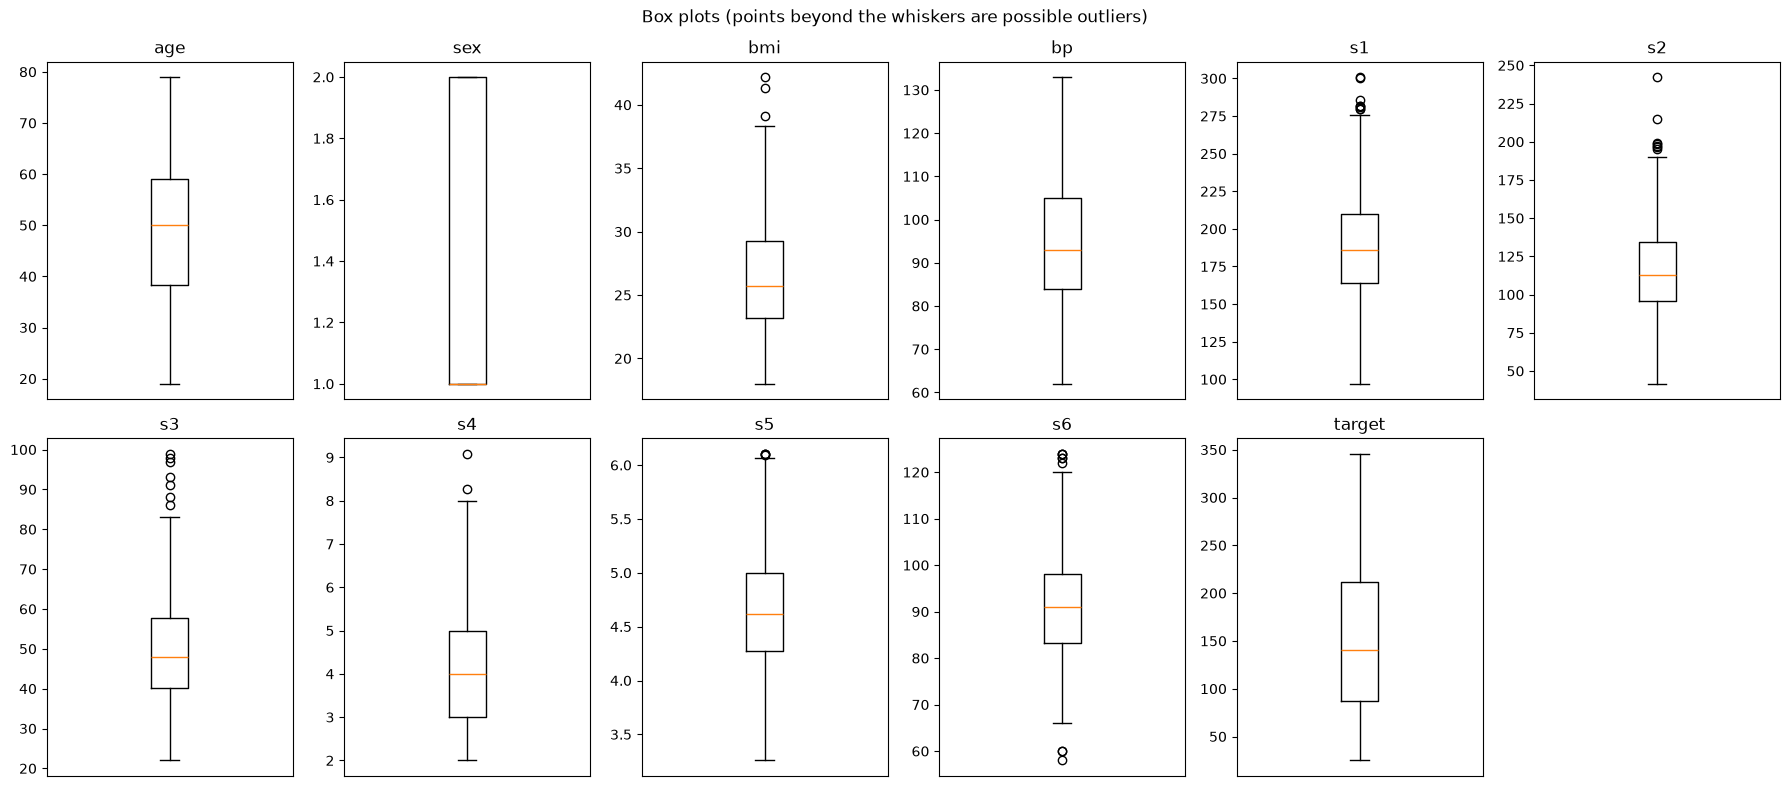

Number of values outside 1.5 x IQR per column:


age       0
sex       0
bmi       3
bp        0
s1        8
s2        7
s3        7
s4        2
s5        4
s6        9
target    0
dtype: int64

In [11]:
explorer.plot_boxplots()
print("Number of values outside 1.5 x IQR per column:")
explorer.count_outliers_iqr()

**Insight:** a few values per column fall outside the 1.5×IQR "whiskers" (at most 9 in s6, none in the target).
They are within realistic medical ranges (e.g. BMI 42 is high but common), so they look like **real patients, not errors**.

### EDA summary
1. Clean, complete, small dataset: 442 patients, 10 numeric features, no missing values.
2. **BMI and s5** are the best single predictors; **sex** is almost unrelated to the target.
3. **s1 and s2 are almost duplicates** (r = 0.90).
4. Relationships look mostly **linear**, with **lots of scatter** → we expect moderate R² values (well below 1).
5. Features are on **different scales** → scaling is required for kNN and logistic regression.

## Step 4 – Clean the data

| Check | Result | Action |
|---|---|---|
| Missing values | none | nothing to do |
| Duplicate rows | none | nothing to do |
| Data types | all numeric | nothing to do – sklearn models accept them directly |
| `sex` coded 1/2 | binary category stored as a number | keep as is: with only two values, a single numeric column works the same as a 0/1 dummy |
| Outliers | a few, but medically plausible | **keep them** – removing real patients would make the model worse at exactly the extreme cases a screening tool should catch, and with only 442 rows every patient counts |
| Different feature scales | yes | **not done here**. Scaling is done *inside* each model's Pipeline, fitted on the **training data only**. Scaling the whole dataset now would let information from the validation/test sets "leak" into training. |

**Conclusion:** the dataset is already clean (sklearn provides it pre-processed), so **no rows or values need to be changed**.

**Feature selection for Part 3** (decided now, from the EDA):
* **Drop `sex`** – correlation with the target is only 0.04 (almost no signal; for kNN it would just add noise to the distances).
* **Drop `s2`** – it is 0.90 correlated with `s1` (redundant), and it is the weaker of the two with the target (0.17 vs 0.21).
* Keep the other **8 features**: age, bmi, bp, s1, s3, s4, s5, s6.

Fewer, more useful features also matter for polynomial models: the number of polynomial terms grows very quickly with the number of features.

In [12]:
X, y = loader.get_features_and_target()

# Features used in Part 3 (multivariate models)
DROPPED_FEATURES = ["sex", "s2"]
MULTI_FEATURES = [col for col in X.columns if col not in DROPPED_FEATURES]
print("Features for Part 3:", MULTI_FEATURES)

Features for Part 3: ['age', 'bmi', 'bp', 's1', 's3', 's4', 's5', 's6']


## Step 5 – Split the data: train (75%), validation (10%), test (15%)

**Why three sets?**
* **Train** – the model learns from these patients.
* **Validation** – used to **compare models and choose** the best one (e.g. which polynomial degree).
* **Test** – kept locked away until the very end and used **only once** on the chosen model. It gives an honest estimate of how the model will do on new patients.
  If we used the test set to choose the model, we would be "fitting to the test" and our estimate would be too optimistic.

`train_test_split` can only make two parts, so our `DataSplitter` class calls it twice:
first it cuts off 15% for testing, then it splits the remaining 85% into train and validation
(10% of the total = 0.10 / 0.85 ≈ 11.8% of the remainder). `random_state=42` makes the split the same every time we run the notebook.

In [13]:
splitter = DataSplitter(val_size=0.10, test_size=0.15, random_state=RANDOM_STATE)
X_train, X_val, X_test, y_train, y_val, y_test = splitter.split(X, y)

splitter.describe_split(X_train, X_val, X_test)

Train      : 330 rows (74.7%)
Validation :  45 rows (10.2%)
Test       :  67 rows (15.2%)


The percentages are as close to 75 / 10 / 15 as possible with 442 whole patients.

---
# Part 2 – Univariate Polynomial Regression on BMI

## Step 6 – Build the models (degree 0 to 5)

A polynomial of degree *d* on BMI is:

$$\text{progression} = b_0 + b_1\cdot \text{bmi} + b_2\cdot \text{bmi}^2 + \dots + b_d\cdot \text{bmi}^d$$

* **Degree 0** → a flat line: always predicts the average (our baseline).
* **Degree 1** → a straight line (simple linear regression).
* **Degree 2–5** → curves that can bend more and more.

How it works in code (see `ModelBuilder.univariate_polynomial`): a **Pipeline** with two steps:
1. `PolynomialFeatures(degree)` turns the single column `bmi` into the columns `1, bmi, bmi², …, bmiᵈ`.
2. `LinearRegression` finds the best coefficient for each column (least squares).

So a "polynomial regression" is really a **linear regression on extra, powered columns**.

Note: we pass `X_train[["bmi"]]` with **double brackets**, which keeps it a DataFrame (2-D table). sklearn always expects a 2-D input, even for one feature.

In [14]:
builder = ModelBuilder(random_state=RANDOM_STATE)
UNI_FEATURE = ["bmi"]

# Build and train the 6 models, storing them in a dictionary: {"Degree 0": model, ...}
uni_models = {}
for degree in range(0, 6):
    model = builder.univariate_polynomial(degree)
    model.fit(X_train[UNI_FEATURE], y_train)          # learn ONLY from the training set
    uni_models[f"Degree {degree}"] = model

print("Trained models:", list(uni_models.keys()))

Trained models: ['Degree 0', 'Degree 1', 'Degree 2', 'Degree 3', 'Degree 4', 'Degree 5']


## Step 7 – Compare the models on training and validation data

For each model we calculate R², MAE and MAPE on the **training** set (how well it fits what it has seen)
and on the **validation** set (how well it works on new patients). Each model is one row.

In [15]:
uni_evaluator = ModelEvaluator()
for name, model in uni_models.items():
    n_params, _ = builder.count_trainable_parameters(model)
    uni_evaluator.add_regression_result(name, model,
                                        X_train[UNI_FEATURE], y_train,
                                        X_val[UNI_FEATURE], y_val,
                                        n_params=n_params)

uni_table = uni_evaluator.results_table(decimals=4)
uni_table

,Parameters,Train R2,Train MAE,Train MAPE (%),Val R2,Val MAE,Val MAPE (%)
Model,,,,,,,
Degree 0,1,0.0000,66.5482,63.3521,-0.0000,63.4475,58.7933
Degree 1,2,0.3542,52.2781,48.4624,0.4493,41.9976,40.4450
Degree 2,3,0.3548,52.2673,48.4479,0.4492,41.7577,40.3099
Degree 3,4,0.3549,52.2389,48.3953,0.4483,41.7652,40.2905
Degree 4,5,0.3549,52.2429,48.3981,0.4477,41.7373,40.2760
Degree 5,6,0.3552,52.2315,48.4079,0.4494,41.8024,40.3208


**How to read the table**
* **Degree 0** has R² = 0 on training by definition (it just predicts the mean): MAE ≈ 66, MAPE ≈ 63%. This is the baseline.
* Moving to **degree 1** is a big improvement: validation R² jumps to ≈ 0.45, MAE drops from ≈ 63 to ≈ 42.
* **Degrees 2 to 5 add almost nothing.** Validation R² stays at 0.448–0.449 and MAE changes by less than 0.3 units.
  Training R² rises very slightly (0.3542 → 0.3552) – the extra flexibility only fits tiny bits of noise.
  This agrees with the EDA: the BMI–progression relationship is basically **a straight line**.
* Validation scores are a bit *higher* than training scores. This does not mean the model is "better than perfect" on new data; the validation set is small (45 patients)
  and by chance happens to be a slightly easier group. This is a reminder that **scores on small sets are noisy**.

## Step 8 – Identify the best model

**Rule we use:** take the model with the highest validation R², **but** if several models are practically tied
(within 0.01 of the best R²), choose the **simplest** one (fewest parameters).
This is the principle of **parsimony (Occam's razor)**: a simpler model is easier to explain to physicians and less likely to behave strangely on new data.

In [16]:
TOLERANCE = 0.01
best_val_r2 = uni_table["Val R2"].max()

# all models whose validation R2 is within the tolerance of the best one
candidates = uni_table[uni_table["Val R2"] >= best_val_r2 - TOLERANCE]
best_uni_name = candidates["Parameters"].idxmin()      # the simplest of them
best_uni_model = uni_models[best_uni_name]

print(f"Highest validation R2: {best_val_r2:.4f} ({uni_table['Val R2'].idxmax()})")
print(f"Practically tied models: {list(candidates.index)}")
print(f"Chosen model: {best_uni_name}")

Highest validation R2: 0.4494 (Degree 5)
Practically tied models: ['Degree 1', 'Degree 2', 'Degree 3', 'Degree 4', 'Degree 5']
Chosen model: Degree 1


**Chosen model: Degree 1 (a straight line).** Degree 5 has the highest validation R², but only by 0.0001 – far less than the noise of a 45-patient
validation set. Degree 2 has a slightly lower MAE (by 0.24 units, which is nothing next to an error of ~42). Degree 1 performs the same with only 2 parameters
instead of 6, so it is the best choice.

## Step 9 – Run the chosen model on the test set

Now – and only now – we use the test set, once.

In [17]:
y_test_pred_uni = best_uni_model.predict(X_test[UNI_FEATURE])
uni_test_metrics = ModelEvaluator.regression_metrics(y_test, y_test_pred_uni)

pd.DataFrame(uni_test_metrics, index=[f"{best_uni_name} - TEST"]).round(3)

,R2,MAE,MAPE (%)
Degree 1 - TEST,0.204,54.934,48.75


**Test results:** R² ≈ 0.20, MAE ≈ 54.9, MAPE ≈ 48.7%.

This is clearly **worse than on validation** (R² 0.45, MAE 42). Possible reasons:
* The test set (67 patients) happens to contain more patients whose progression BMI cannot explain (see the residual analysis in Step 14).
* Small sets make scores jump around: changing a few patients can move R² a lot.

The honest summary is: **BMI alone explains only about 20–45% of the variation in progression**, and the typical error is around 40–55 units.

## Step 10 – Plot train, validation and test data with the model's fit

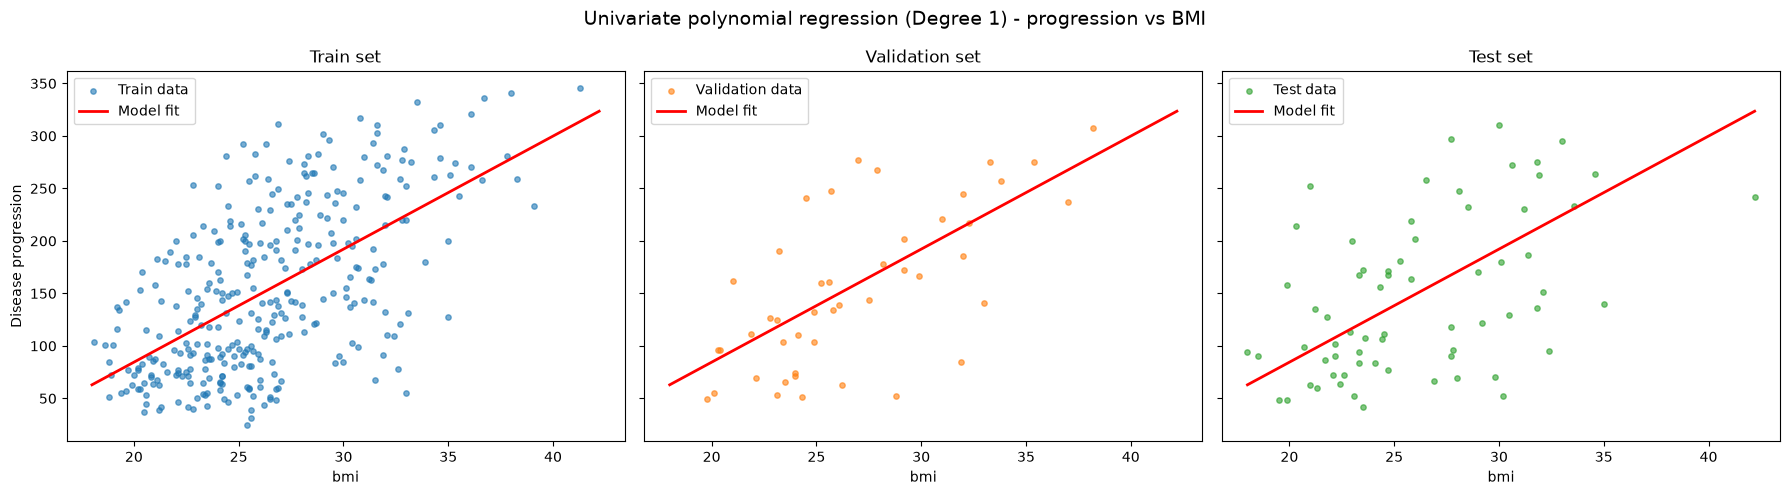

In [18]:
ModelEvaluator.plot_univariate_fit(
    best_uni_model,
    feature="bmi",
    datasets={
        "Train": (X_train, y_train),
        "Validation": (X_val, y_val),
        "Test": (X_test, y_test),
    },
    title=f"Univariate polynomial regression ({best_uni_name}) - progression vs BMI",
)

The red line is the same in all three panels (the model learned it from the training data only).
It follows the general upward trend, but in every set the points are **spread far above and below the line** – the model gets the *direction* right but cannot
predict individual patients precisely.

For comparison, here are all six degrees on the training data – they are almost on top of each other inside the data range:

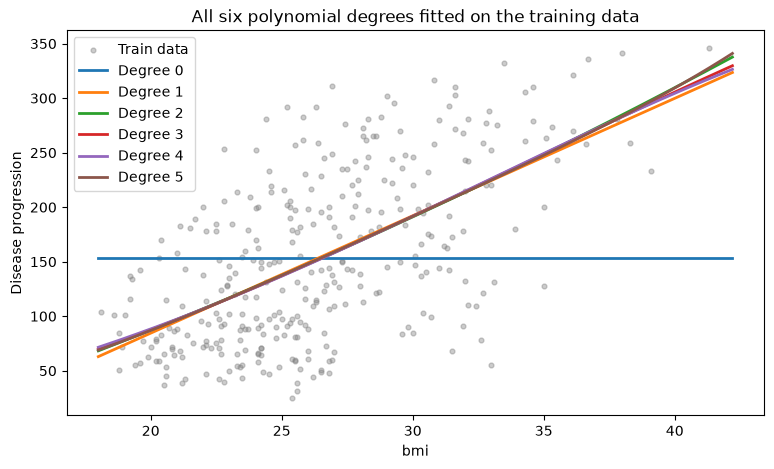

In [19]:
x_line = pd.DataFrame({"bmi": np.linspace(X["bmi"].min(), X["bmi"].max(), 200)})

plt.figure(figsize=(9, 5))
plt.scatter(X_train["bmi"], y_train, alpha=0.4, s=12, color="gray", label="Train data")
for name, model in uni_models.items():
    plt.plot(x_line["bmi"], model.predict(x_line), linewidth=2, label=name)
plt.xlabel("bmi")
plt.ylabel("Disease progression")
plt.title("All six polynomial degrees fitted on the training data")
plt.legend()
plt.show()

## Step 11 – Equation of the best model

`ModelBuilder.polynomial_equation` reads the column names (`get_feature_names_out()`) and the fitted coefficients (`coef_`) and writes them as an equation.

In [20]:
print(builder.polynomial_equation(best_uni_model, decimals=2))

progression = -130.87 + 10.77*bmi


$$\text{progression} = -130.87 + 10.77 \times \text{BMI}$$

**Interpretation:** each extra BMI unit (1 kg/m²) adds about **10.8 units** of expected disease progression after one year.
The intercept (−130.87) has no medical meaning on its own (nobody has BMI = 0); it just positions the line.

## Step 12 – Predict progression for a chosen BMI

We choose **BMI = 30**, the threshold for obesity according to the WHO.
The input must have the same format as during training: a DataFrame with a column named `bmi`.

In [21]:
chosen_bmi = 30
new_patient = pd.DataFrame({"bmi": [chosen_bmi]})

predicted = best_uni_model.predict(new_patient)[0]
print(f"Expected disease progression for BMI = {chosen_bmi}: {predicted:.2f}")

# Check by hand with the equation from Step 11 (rounded coefficients -> tiny difference)
print(f"By hand: -130.87 + 10.77 * {chosen_bmi} = {-130.87 + 10.77 * chosen_bmi:.2f}")

Expected disease progression for BMI = 30: 192.17
By hand: -130.87 + 10.77 * 30 = 192.23


A patient with BMI 30 is expected to have a progression of about **192**, which is above the dataset average (≈ 152).
Keep in mind the typical error of ±40–55 units (MAE), so this is an *estimate of risk*, not an exact value.

## Step 13 – Number of trainable parameters per model

A **trainable parameter** is a number the model *learns* from data (here: the coefficients $b_0, b_1, \dots$).
`get_feature_names_out()` lists the columns created by `PolynomialFeatures`; each column gets exactly one learned coefficient.

In [22]:
param_rows = []
for name, model in uni_models.items():
    feature_names = model.named_steps["poly"].get_feature_names_out()
    n_params, explanation = builder.count_trainable_parameters(model)
    param_rows.append({
        "Model": name,
        "Columns created (get_feature_names_out)": ", ".join(feature_names),
        "Trainable parameters": n_params,
    })

pd.DataFrame(param_rows).set_index("Model")

,Columns created (get_feature_names_out),Trainable parameters
Model,,
Degree 0,1,1
Degree 1,"1, bmi",2
Degree 2,"1, bmi, bmi^2",3
Degree 3,"1, bmi, bmi^2, bmi^3",4
Degree 4,"1, bmi, bmi^2, bmi^3, bmi^4",5
Degree 5,"1, bmi, bmi^2, bmi^3, bmi^4, bmi^5",6


**Explanation:** a polynomial of degree *d* in one variable has **d + 1 parameters**: one intercept ($b_0$, the coefficient of the column `1`)
plus one coefficient for each power of BMI (bmi, bmi², …, bmiᵈ). So degree 0 → 1 parameter (just the mean), degree 1 → 2 (intercept + slope), …, degree 5 → 6.

*Technical note:* we let `PolynomialFeatures` create the column `1` and set `LinearRegression(fit_intercept=False)`, so the intercept is learned exactly
once (as the coefficient of `1`). Otherwise the intercept would be counted twice.

## Step 14 – Conclusion (Part 2)

### Where does the model fail?
We split the test patients into three groups by their **true** progression and compare the errors:

In [23]:
PROGRESSION_BINS = [0, 100, 200, 400]
PROGRESSION_LABELS = ["Low (<100)", "Medium (100-200)", "High (>200)"]

ModelEvaluator.error_by_group(y_test, y_test_pred_uni, PROGRESSION_BINS, PROGRESSION_LABELS)

,patients,mean_actual,mean_predicted,mean_error,MAE,MAPE_pct
group,,,,,,
Low (<100),25,74.4,125.3,50.9,55.7,82.8
Medium (100-200),25,147.0,149.9,2.9,40.3,27.7
High (>200),17,253.3,187.6,-65.7,75.3,29.6


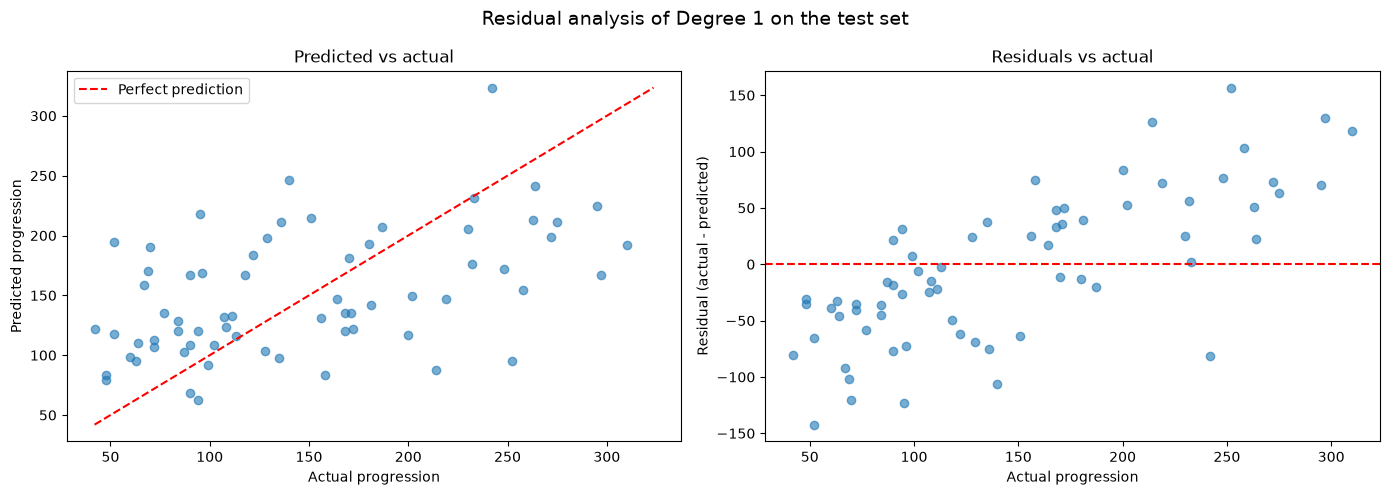

In [24]:
ModelEvaluator.plot_residuals(y_test, y_test_pred_uni,
                              title=f"Residual analysis of {best_uni_name} on the test set")

**Analysis of failures**
* **Medium-progression patients (100–200):** predicted well on average (mean error ≈ +3), MAPE ≈ 28%.
* **Low-progression patients (<100):** strongly **over-predicted** (by ≈ +51 on average, MAPE ≈ 83%). Because the true values are small,
  even moderate errors become huge percentages – this is what pushes the overall MAPE up.
* **High-progression patients (>200):** strongly **under-predicted** (by ≈ −66 on average, the largest MAE ≈ 75).
  **This is the most worrying failure for a screening tool**: the patients who progress the most are the ones the model underestimates.
* The residual plot shows a clear **diagonal pattern**: residuals go from negative to positive as the true value grows. The predictions are
  "squeezed" towards the average (≈ 125–190) – the model cannot produce very low or very high values because BMI alone does not carry enough information.
* The fit also only covers BMI 18–42: predictions outside that range (**extrapolation**) would not be reliable.

### Summary of performance
* BMI is a real, useful predictor: the straight line clearly beats the baseline (validation MAE 42 vs 63).
* Higher polynomial degrees bring **no improvement** – the relationship is linear, and extra parameters would only fit noise.
* On the unseen test set the model explains only **≈ 20%** of the variation (R² 0.20, MAE ≈ 55, MAPE ≈ 49%).

### Limitations
1. **One feature only.** Progression depends on many factors (blood sugar, triglycerides, blood pressure…); BMI alone misses most of them.
2. **Small dataset** (442 patients; validation set of 45). Scores change noticeably depending on which patients land in which set
   (validation R² 0.45 vs test R² 0.20). Cross-validation would give a more stable estimate.
3. **Regression to the mean**: extreme patients are predicted too close to the average, exactly where screening matters most.
4. **Unknown target scale.** The target is "a quantitative measure" without clinical units, which makes errors harder to interpret medically.
5. **Correlation is not causation** – the model says patients with higher BMI tend to progress more, not that BMI alone causes it.

### Link to the workshops
* *Performance Metrics:* a regression model can be turned into a screening rule ("flag if predicted progression > threshold").
  Because it under-predicts the high group, such a rule would produce many **false negatives** (low **recall**) – the costliest mistake in screening.
* *KNN:* a non-linear method like kNN could capture patterns a straight line misses, but with only one feature there is little more to find.
* *Logistic Regression:* if physicians only need "high risk yes/no", a classifier that directly outputs a **probability** of high risk, with an adjustable threshold, may be more useful than an exact progression number (Part 3).

---
# Part 3 – Multivariate Models

We now use **8 features** (all except `sex` and `s2`, as decided in Step 4) and repeat the steps for:

| Family | Model A | Model B | Why these two settings? |
|---|---|---|---|
| Polynomial regression | degree 2 | degree 3 | degree 1 would be plain linear regression (the lab asks for degree > 1) |
| Decision tree | `max_depth=3` | `max_depth=5` | a shallow vs. a deeper tree – shows the effect of model complexity |
| kNN | `k=5` | `k=15` | few neighbours (flexible) vs. many neighbours (smooth) |
| Logistic regression | `C=1.0` | `C=0.01` | weak vs. strong regularisation |

The first three families are **regressors** (predict the progression number). Logistic regression is a **classifier**, so it gets its own section (Part 3B).

## Part 3A – Regression models

### Step 6 – Build and train the models

In [25]:
multi_models = {
    "Polynomial (degree 2)": builder.multivariate_polynomial(degree=2),
    "Polynomial (degree 3)": builder.multivariate_polynomial(degree=3),
    "Decision tree (max_depth=3)": builder.decision_tree(max_depth=3),
    "Decision tree (max_depth=5)": builder.decision_tree(max_depth=5),
    "kNN (k=5)": builder.knn(n_neighbors=5),
    "kNN (k=15)": builder.knn(n_neighbors=15),
}

X_train_m, X_val_m, X_test_m = X_train[MULTI_FEATURES], X_val[MULTI_FEATURES], X_test[MULTI_FEATURES]

for name, model in multi_models.items():
    model.fit(X_train_m, y_train)
print("All models trained.")

All models trained.


### Step 7 – Compare the models on training and validation data

We also add the univariate **BMI-only line** from Part 2 as a reference row, to see whether more features help.

In [26]:
multi_evaluator = ModelEvaluator()

# reference row: the best model from Part 2
multi_evaluator.add_regression_result(f"Reference: BMI only ({best_uni_name})", best_uni_model,
                                      X_train[UNI_FEATURE], y_train, X_val[UNI_FEATURE], y_val,
                                      n_params=builder.count_trainable_parameters(best_uni_model)[0])

for name, model in multi_models.items():
    n_params, _ = builder.count_trainable_parameters(model)
    multi_evaluator.add_regression_result(name, model, X_train_m, y_train, X_val_m, y_val,
                                          n_params=n_params)

multi_table = multi_evaluator.results_table(decimals=3)
multi_table

,Parameters,Train R2,Train MAE,Train MAPE (%),Val R2,Val MAE,Val MAPE (%)
Model,,,,,,,
Reference: BMI only (Degree 1),2,0.354,52.278,48.462,0.449,41.998,40.445
Polynomial (degree 2),45,0.555,42.501,37.623,0.508,42.248,45.487
Polynomial (degree 3),165,0.733,31.168,28.085,-0.325,70.788,68.203
Decision tree (max_depth=3),22,0.531,43.669,37.809,0.392,43.411,44.079
Decision tree (max_depth=5),94,0.704,33.079,28.843,0.124,50.516,52.137
kNN (k=5),0,0.555,41.179,35.109,0.511,41.276,41.434
kNN (k=15),0,0.490,45.274,39.665,0.540,40.627,40.550


**How to read the table – overfitting vs. a good fit**

The key is to compare the **train** columns with the **val** columns:
* **Polynomial degree 3** – train R² 0.73 but validation R² **−0.33** (worse than predicting the average!). With 8 features, degree 3 creates 164 columns
  → 165 parameters for only 330 training patients. The model **memorises** the training data, including its noise: a textbook case of **overfitting**.
* **Decision tree depth 5** – same story: train R² 0.70, validation only 0.12. A deep tree builds very specific rules that do not generalise.
* **Decision tree depth 3** – less overfitting, but its validation R² (0.39) is still below the BMI-only line.
* **Polynomial degree 2** – validation R² 0.51, better than BMI only, with a moderate gap to training.
* **kNN** – the best validation results. **k=15** reaches the highest validation R² (0.54) and lowest validation MAE (40.6) and MAPE (40.6%).
  k=5 fits the training data more closely (train R² 0.56) but does worse on validation – small k follows the noise more (as discussed in the kNN workshop).

**Overall:** using more features *does* help (0.45 → 0.54 validation R²), but only with models that control their complexity.

### Step 8 – Identify the best model
Same rule as in Part 2: highest validation R², and the simplest model if several are tied (within 0.01).

In [27]:
multi_only = multi_table.drop(index=multi_table.index[0])          # leave out the reference row

best_val_r2_m = multi_only["Val R2"].max()
candidates_m = multi_only[multi_only["Val R2"] >= best_val_r2_m - TOLERANCE]
best_multi_name = candidates_m["Parameters"].idxmin()
best_multi_model = multi_models[best_multi_name]

print(f"Highest validation R2: {best_val_r2_m:.3f}")
print(f"Practically tied models: {list(candidates_m.index)}")
print(f"Chosen model: {best_multi_name}")

Highest validation R2: 0.540
Practically tied models: ['kNN (k=15)']
Chosen model: kNN (k=15)


**Chosen model: kNN with k = 15.** It has the best validation R², MAE and MAPE, and the smallest train–validation gap of the strong models.

### Step 9 – Run the chosen model on the test set

In [28]:
y_test_pred_multi = best_multi_model.predict(X_test_m)
multi_test_metrics = ModelEvaluator.regression_metrics(y_test, y_test_pred_multi)

test_comparison = pd.DataFrame(
    [uni_test_metrics, multi_test_metrics],
    index=[f"Part 2: BMI only ({best_uni_name}) - TEST", f"Part 3: {best_multi_name} - TEST"],
).round(3)
test_comparison

,R2,MAE,MAPE (%)
Part 2: BMI only (Degree 1) - TEST,0.204,54.934,48.750
Part 3: kNN (k=15) - TEST,0.409,44.984,38.801


On the test set the kNN model reaches **R² ≈ 0.41, MAE ≈ 45, MAPE ≈ 38.8%**. Compared with the BMI-only model on the **same test patients**,
R² roughly **doubles** (0.20 → 0.41) and MAE drops by about 10 units. Like in Part 2, the test scores are lower than the validation scores, confirming that
this test set is a harder group of patients and that small sets give noisy scores.

### Step 10 – Plot
Not required for multivariate models (we cannot draw an 8-dimensional fit). The residual plot in Step 14 shows the predictions instead.

### Step 11 – Equation of the best model
**kNN has no equation.** It does not learn coefficients; to predict, it finds the 15 training patients closest to the new patient
(after scaling the 8 features) and returns the **average** of their progression:

$$\hat{y} = \frac{1}{15}\sum_{i \in \text{15 nearest neighbours}} y_i$$

(The degree-2 polynomial does have an equation, but with 45 terms it would not be readable or useful to a physician.)

### Step 12 – Prediction for a chosen patient
We create a "typical" patient (the **median** of every training feature) and set **BMI = 30**, the same value as in Part 2, so we can compare.

In [29]:
typical_patient = X_train_m.median().to_frame().T     # one-row DataFrame with the median of each feature
typical_patient["bmi"] = chosen_bmi
display(typical_patient)

pred_multi = best_multi_model.predict(typical_patient)[0]
print(f"{best_multi_name} prediction for this patient: {pred_multi:.2f}")
print(f"Part 2 BMI-only prediction for BMI = {chosen_bmi}: {predicted:.2f}")

,age,bmi,bp,s1,s3,s4,s5,s6
0,50.0,30,93.0,186.0,48.0,4.0,4.62985,91.0


kNN (k=15) prediction for this patient: 183.93
Part 2 BMI-only prediction for BMI = 30: 192.17


The multivariate model predicts a lower value than the BMI-only line. This makes sense: apart from the high BMI, this patient has *average* blood pressure,
triglycerides, etc. The BMI-only model cannot know that – it effectively assumes that high-BMI patients also have the other risk factors that usually come with a high BMI.

### Step 13 – Number of trainable parameters

In [30]:
param_rows_m = []
for name, model in multi_models.items():
    n_params, explanation = builder.count_trainable_parameters(model)
    param_rows_m.append({"Model": name, "Trainable parameters": n_params, "Explanation": explanation})

pd.set_option("display.max_colwidth", None)
pd.DataFrame(param_rows_m).set_index("Model")

,Trainable parameters,Explanation
Model,,
Polynomial (degree 2),45,44 coefficients + 1 intercept
Polynomial (degree 3),165,164 coefficients + 1 intercept
Decision tree (max_depth=3),22,"7 splits x (feature + threshold) + 8 leaf values (non-parametric: learned structure, not fixed weights)"
Decision tree (max_depth=5),94,"31 splits x (feature + threshold) + 32 leaf values (non-parametric: learned structure, not fixed weights)"
kNN (k=5),0,0 learned parameters - kNN just stores the training data (k is a hyperparameter)
kNN (k=15),0,0 learned parameters - kNN just stores the training data (k is a hyperparameter)


In [31]:
# get_feature_names_out() shows which columns the degree-2 polynomial creates.
# The scaler step removes column names, so we pass the original names in ourselves.
poly2_names = multi_models["Polynomial (degree 2)"].named_steps["poly"].get_feature_names_out(MULTI_FEATURES)
print(f"Degree 2 creates {len(poly2_names)} columns, e.g.: {list(poly2_names[:10])} ...")
poly3_names = multi_models["Polynomial (degree 3)"].named_steps["poly"].get_feature_names_out(MULTI_FEATURES)
print(f"Degree 3 creates {len(poly3_names)} columns")

Degree 2 creates 44 columns, e.g.: ['age', 'bmi', 'bp', 's1', 's3', 's4', 's5', 's6', 'age^2', 'age bmi'] ...
Degree 3 creates 164 columns


**Explanation**
* **Polynomial degree 2 → 45 parameters**: 8 original features + 8 squared terms (bmi²…) + 28 interaction terms (bmi·bp, bmi·s5, …) = 44 coefficients, plus 1 intercept.
* **Polynomial degree 3 → 165 parameters**: 164 columns + 1 intercept. That is one parameter for every two training patients – far too many, which explains the overfitting.
* **Decision trees** are *non-parametric*: they do not have a fixed set of weights. What they learn is a structure: for every split, *which feature* and *which threshold*,
  and for every leaf, a *prediction value*. Counting those gives 22 (depth 3) and 94 (depth 5). The depth-5 tree has many more learned values, which is why it overfits.
* **kNN → 0 trainable parameters.** It only **stores** the training data. `k` is a *hyperparameter* we choose, not something learned.
  (The `StandardScaler` step does compute the mean and standard deviation of each feature from the training data, but these are pre-processing statistics, not model weights.)

## Part 3B – Logistic Regression (classification)

### Why logistic regression needs a different target
Logistic regression predicts a **class** (0 or 1), not a number like 152.7. So we first turn the target into two classes:

* **1 = High risk** if progression > the **median progression of the training set**
* **0 = Low risk** otherwise

**Why the median?** It gives two classes of about equal size (balanced), so accuracy is not misleading. In a real clinic, physicians would set the threshold
based on medical criteria. We calculate it from the **training set only**, so the validation/test data do not influence it (no leakage).

**Why other metrics?** R², MAE and MAPE measure *distances between numbers*. For 0/1 predictions they do not make sense
(the MAE of 0/1 labels is simply the error rate, and MAPE would divide by 0 for low-risk patients). Instead we use the **classification metrics** from the
Performance Metrics workshop: accuracy, precision, **recall** and F1.

In [32]:
RISK_THRESHOLD = y_train.median()
print(f"High-risk threshold (median of training progression): {RISK_THRESHOLD}")

# True/False -> 1/0
y_train_cls = (y_train > RISK_THRESHOLD).astype(int)
y_val_cls = (y_val > RISK_THRESHOLD).astype(int)
y_test_cls = (y_test > RISK_THRESHOLD).astype(int)

print(f"Share of high-risk patients - train: {y_train_cls.mean():.1%}, "
      f"validation: {y_val_cls.mean():.1%}, test: {y_test_cls.mean():.1%}")

High-risk threshold (median of training progression): 142.0
Share of high-risk patients - train: 49.1%, validation: 48.9%, test: 44.8%


The classes are balanced (≈ 45–50% high risk in every set).

### Step 6 – Build and train two logistic regression models
* `C=1.0` – the default, weak regularisation.
* `C=0.01` – strong regularisation: coefficients are pushed towards 0, giving a simpler, more cautious model.

Both pipelines scale the features first (`StandardScaler`), because regularisation penalises coefficients by size, which is only fair if all features are on the same scale.

In [33]:
log_models = {
    "Logistic regression (C=1.0)": builder.logistic_regression(C=1.0),
    "Logistic regression (C=0.01)": builder.logistic_regression(C=0.01),
}
for name, model in log_models.items():
    model.fit(X_train_m, y_train_cls)
print("Logistic regression models trained.")

Logistic regression models trained.


### Step 7 – Compare the models on training and validation data

In [34]:
log_evaluator = ModelEvaluator()
for name, model in log_models.items():
    n_params, _ = builder.count_trainable_parameters(model)
    log_evaluator.add_classification_result(name, model, X_train_m, y_train_cls, X_val_m, y_val_cls,
                                            n_params=n_params)

log_table = log_evaluator.results_table(decimals=3)
log_table

,Parameters,Train Accuracy,Train Precision,Train Recall,Train F1,Val Accuracy,Val Precision,Val Recall,Val F1
Model,,,,,,,,,
Logistic regression (C=1.0),9,0.733,0.74,0.704,0.722,0.822,0.818,0.818,0.818
Logistic regression (C=0.01),9,0.727,0.72,0.728,0.724,0.822,0.792,0.864,0.826


* Both models classify about **73% of training** and **82% of validation** patients correctly – similar on both sets, so **no overfitting**
  (only 9 parameters each).
* They have the same validation accuracy, but **C=0.01 has the higher recall (0.864 vs 0.818)**: it catches more of the truly high-risk patients,
  at the cost of slightly lower precision.

### Step 8 – Identify the best model
For a screening tool, missing a high-risk patient (false negative) is the most costly error, so we choose by **validation recall**
(and F1 as a tie-breaker so we don't pick a model that simply flags everyone).

In [35]:
best_log_name = log_table.sort_values(["Val Recall", "Val F1"], ascending=False).index[0]
best_log_model = log_models[best_log_name]
print(f"Chosen classifier: {best_log_name}")

Chosen classifier: Logistic regression (C=0.01)


### Step 9 – Run the chosen classifier on the test set

,Accuracy,Precision,Recall,F1
Logistic regression (C=0.01) - TEST,0.791,0.767,0.767,0.767


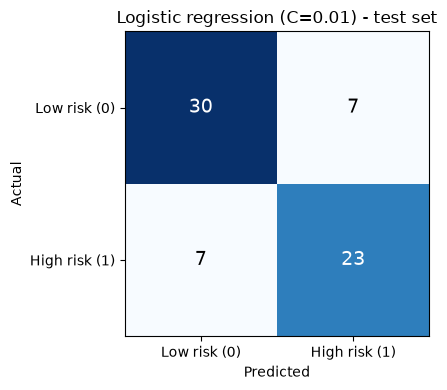

True negatives: 30, False positives: 7, False negatives: 7, True positives: 23


In [36]:
y_test_pred_cls = best_log_model.predict(X_test_m)
log_test_metrics = ModelEvaluator.classification_metrics(y_test_cls, y_test_pred_cls)
display(pd.DataFrame(log_test_metrics, index=[f"{best_log_name} - TEST"]).round(3))

cm = ModelEvaluator.plot_confusion_matrix(y_test_cls, y_test_pred_cls,
                                          title=f"{best_log_name} - test set")
tn, fp, fn, tp = cm.ravel()
print(f"True negatives: {tn}, False positives: {fp}, False negatives: {fn}, True positives: {tp}")

On the 67 test patients: **accuracy ≈ 79%, precision ≈ 0.77, recall ≈ 0.77, F1 ≈ 0.77**.
Of the 30 truly high-risk patients, **23 are caught** and **7 are missed** (false negatives). 7 low-risk patients are flagged unnecessarily (false positives).

**Can we use the regression model as a screener too?** We apply the same threshold to the kNN predictions, to compare on equal terms:

In [37]:
knn_as_classifier = (y_test_pred_multi > RISK_THRESHOLD).astype(int)
screening_comparison = pd.DataFrame(
    [log_test_metrics, ModelEvaluator.classification_metrics(y_test_cls, knn_as_classifier)],
    index=[f"{best_log_name}", f"{best_multi_name} + threshold {RISK_THRESHOLD}"],
).round(3)
screening_comparison

,Accuracy,Precision,Recall,F1
Logistic regression (C=0.01),0.791,0.767,0.767,0.767
kNN (k=15) + threshold 142.0,0.761,0.706,0.800,0.750


Both approaches give similar screening quality on the test set. The kNN rule happens to catch one more high-risk patient (recall 0.80) but raises more false alarms (precision 0.71).
The logistic model has the advantage of returning a **probability**, whose threshold can be tuned (see below).

### Step 10 – Plot
Not required for multivariate models; the confusion matrix above summarises the predictions.

### Step 11 – Equation of the chosen classifier
Logistic regression **does** have an equation. It first computes a linear score *z* (the log-odds), then the sigmoid turns it into a probability:

$$P(\text{high risk}) = \frac{1}{1 + e^{-z}}$$

Because the features are standardised, each variable in *z* is a **z-score** (how many standard deviations above the training average the patient is):

In [38]:
logreg = best_log_model.named_steps["logreg"]
terms = " ".join(f"{'+' if c >= 0 else '-'} {abs(c):.2f}*{f}_std" for c, f in zip(logreg.coef_[0], MULTI_FEATURES))
print(f"z = {logreg.intercept_[0]:.2f} {terms}")

coef_table = pd.Series(logreg.coef_[0], index=MULTI_FEATURES, name="coefficient").sort_values(key=abs, ascending=False)
coef_table.round(2).to_frame()

z = -0.04 + 0.08*age_std + 0.28*bmi_std + 0.22*bp_std - 0.01*s1_std - 0.14*s3_std + 0.10*s4_std + 0.25*s5_std + 0.12*s6_std


,coefficient
bmi,0.28
s5,0.25
bp,0.22
s3,-0.14
s6,0.12
s4,0.10
age,0.08
s1,-0.01


**Interpretation:** the largest positive weights are **bmi (0.28), s5 (0.25) and bp (0.22)** – higher BMI, triglycerides and blood pressure increase the probability of being high risk.
**s3 (HDL, the "good" cholesterol)** has a negative weight (−0.14): more HDL lowers the risk. **s1** is almost 0 – once the other blood values are in the model,
total cholesterol adds no extra information. This agrees with the EDA correlations. Because the strong regularisation (C = 0.01) shrinks all weights, they are small numbers.

### Step 12 – Prediction for the same patient

In [39]:
prob_high = best_log_model.predict_proba(typical_patient)[0, 1]      # column 1 = probability of class 1
label = best_log_model.predict(typical_patient)[0]
print(f"Probability of high risk: {prob_high:.1%} -> predicted class: {label} "
      f"({'High risk' if label == 1 else 'Low risk'})")

Probability of high risk: 54.6% -> predicted class: 1 (High risk)


### Step 13 – Number of trainable parameters
Each logistic model learns **9 parameters**: one weight per feature (8) + 1 intercept. The value of `C` changes *how big* the weights can get, not *how many* there are.

In [40]:
for name, model in log_models.items():
    n_params, explanation = builder.count_trainable_parameters(model)
    print(f"{name}: {n_params} parameters ({explanation})")

Logistic regression (C=1.0): 9 parameters (8 feature weights + 1 intercept)
Logistic regression (C=0.01): 9 parameters (8 feature weights + 1 intercept)


**Bonus – adjusting the threshold for screening** (Logistic Regression workshop): by lowering the probability threshold from 0.5 we flag more patients, raising recall.
We look at this on the **validation** set (the test set stays reserved for the final evaluation above).

In [41]:
val_probs = best_log_model.predict_proba(X_val_m)[:, 1]
threshold_rows = []
for t in [0.5, 0.4, 0.3]:
    metrics = ModelEvaluator.classification_metrics(y_val_cls, (val_probs >= t).astype(int))
    threshold_rows.append({"Probability threshold": t, **metrics})
pd.DataFrame(threshold_rows).set_index("Probability threshold").round(3)

,Accuracy,Precision,Recall,F1
Probability threshold,,,,
0.5,0.822,0.792,0.864,0.826
0.4,0.622,0.576,0.864,0.691
0.3,0.644,0.579,1.000,0.733


A lower threshold catches more high-risk patients (higher recall) but flags more low-risk ones (lower precision). Here, lowering it to 0.3 catches **every** high-risk
validation patient (recall 1.0), but precision drops to ≈ 0.58 (many more unnecessary check-ups). Where to set it is a **clinical decision**:
how many extra check-ups is it worth to avoid missing one patient at risk?

## Step 14 – Conclusion (Part 3) and Final Conclusions

### Where does the best regression model fail?

In [42]:
ModelEvaluator.error_by_group(y_test, y_test_pred_multi, PROGRESSION_BINS, PROGRESSION_LABELS)

,patients,mean_actual,mean_predicted,mean_error,MAE,MAPE_pct
group,,,,,,
Low (<100),25,74.4,116.9,42.5,44.3,65.6
Medium (100-200),25,147.0,144.1,-2.9,30.5,20.8
High (>200),17,253.3,187.3,-66.0,67.3,25.9


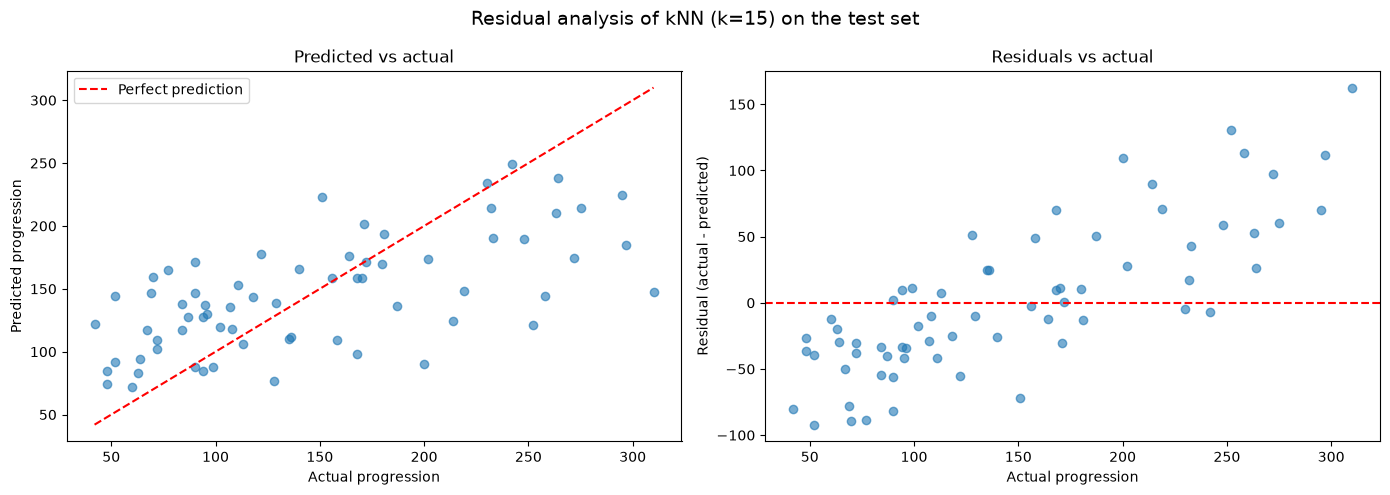

In [43]:
ModelEvaluator.plot_residuals(y_test, y_test_pred_multi,
                              title=f"Residual analysis of {best_multi_name} on the test set")

* kNN improves on the BMI-only model in **every** group (MAE: low 56 → 44, medium 40 → 31, high 75 → 67).
* But the **same pattern** remains: low-progression patients are **over-predicted** (+43 on average) and high-progression patients are **under-predicted** (−66).
  Averaging 15 neighbours makes predictions "regress to the mean": kNN can never predict above the highest values in its neighbourhood, and averaging pulls extremes towards the centre.
* The **high-progression group – the patients a screening tool most needs to find – is still where the errors are largest.**

### Summary of all models
| Model | Validation result | Comment |
|---|---|---|
| Polynomial on BMI, degree 0 | R² 0.00 | baseline (predicts the mean) |
| Polynomial on BMI, degree 1–5 | R² ≈ 0.45 | all equal → choose degree 1; test R² 0.20 |
| Polynomial, 8 features, degree 2 | R² 0.51 | good, but 45 parameters and hard to explain |
| Polynomial, 8 features, degree 3 | R² −0.33 | severe overfitting (165 parameters, 330 patients) |
| Decision tree depth 3 / 5 | R² 0.39 / 0.12 | depth 5 overfits; trees are unstable on small data |
| kNN k = 5 / **k = 15** | R² 0.51 / **0.54** | **best regressor**; test R² 0.41, MAE 45, MAPE 39% |
| **Logistic regression C = 0.01** | recall 0.86, accuracy 0.82 | **best classifier**; test recall 0.77, accuracy 0.79 |

### Recommendation
* As a **screening tool**, the **logistic regression classifier (C = 0.01)** is the most practical choice: it answers the physician's actual question
  ("is this patient at high risk?"), gives a **probability** whose threshold can be tuned to favour recall, has only 9 easy-to-explain parameters, and shows no overfitting.
* If a progression **number** is needed, **kNN (k = 15) on 8 features** is the best regressor and clearly beats the BMI-only model.

### Limitations
1. **Small dataset (442 patients)** – the validation (45) and test (67) sets are small, so scores vary a lot between sets (e.g. kNN: validation R² 0.54, test 0.41).
   **k-fold cross-validation** would give more reliable model comparisons.
2. **Moderate accuracy** – even the best regressor explains only about 40–55% of the variation; ~1 in 4 high-risk patients is still missed by the classifier.
   The model should **support, not replace**, clinical judgement.
3. **Extremes are predicted poorly** – high-progression patients are systematically underestimated.
4. **The high/low threshold (median) is statistical, not clinical**; a real tool needs a medically justified cut-off.
5. **Limited features** – no information on medication, diet, physical activity, family history or HbA1c, which surely affect progression.
6. **Generalisation** – the data come from one study population; the model may not work as well for other populations, and is not reliable outside the observed ranges (e.g. BMI 18–42).
7. **kNN stores all patient data** and must compare with every stored patient at prediction time – a privacy and speed consideration for deployment.

### Talking points from the workshops
* **Performance Metrics:** for screening, **recall** matters more than accuracy because false negatives are the costly error; the confusion matrix makes this trade-off visible.
  Lowering the decision threshold trades precision for recall.
* **K-Nearest Neighbours:** scaling was essential; **k = 15 generalised better than k = 5** (bias–variance trade-off); removing irrelevant features (`sex`) helps distance-based models;
  kNN has no trainable parameters and no equation, which makes it harder to explain to physicians.
* **Logistic Regression:** it outputs **probabilities** via the sigmoid; regularisation (`C`) controls complexity; its coefficients show which risk factors
  (bp, s5, bmi) drive the prediction – a big advantage for **explainability** in medicine.